In [109]:
import warnings

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

from sklearn.tree import DecisionTreeRegressor

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.metrics import r2_score
from sklearn.ensemble import GradientBoostingRegressor

warnings.filterwarnings('ignore')

In [3]:
df = pd.read_csv("concrete_data.csv")

In [4]:
df.head()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [6]:
df.columns

Index(['Cement', 'Blast Furnace Slag', 'Fly Ash', 'Water', 'Superplasticizer',
       'Coarse Aggregate', 'Fine Aggregate', 'Age', 'Strength'],
      dtype='object')

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Cement              1030 non-null   float64
 1   Blast Furnace Slag  1030 non-null   float64
 2   Fly Ash             1030 non-null   float64
 3   Water               1030 non-null   float64
 4   Superplasticizer    1030 non-null   float64
 5   Coarse Aggregate    1030 non-null   float64
 6   Fine Aggregate      1030 non-null   float64
 7   Age                 1030 non-null   int64  
 8   Strength            1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB


In [7]:
df.describe()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.167864,73.895825,54.188350,181.567282,6.204660,972.918932,773.580485,45.662136,35.817961
std,104.506364,86.279342,63.997004,21.354219,5.973841,77.753954,80.175980,63.169912,16.705742
min,102.000000,0.000000,0.000000,121.800000,0.000000,801.000000,594.000000,1.000000,2.330000
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.710000
50%,272.900000,22.000000,0.000000,185.000000,6.400000,968.000000,779.500000,28.000000,34.445000
75%,350.000000,142.950000,118.300000,192.000000,10.200000,1029.400000,824.000000,56.000000,46.135000
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000


In [22]:
df.corr()["Strength"].sort_values(ascending=False)

Strength              1.000000
Cement                0.497832
Superplasticizer      0.366079
Age                   0.328873
Blast Furnace Slag    0.134829
Fly Ash              -0.105755
Coarse Aggregate     -0.164935
Fine Aggregate       -0.167241
Water                -0.289633
Name: Strength, dtype: float64

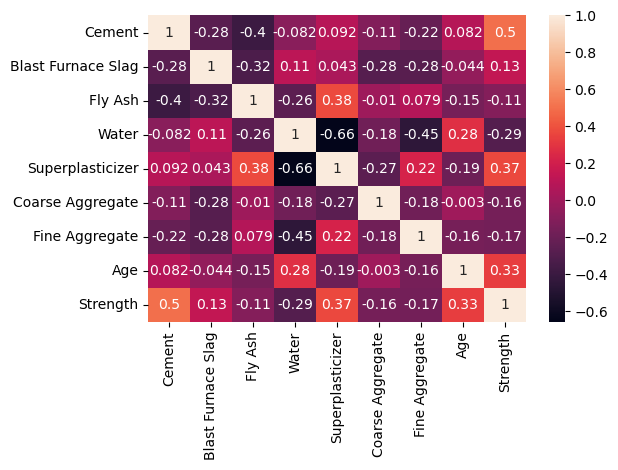

In [20]:
sns.heatmap(df.corr(), annot=True)
plt.tight_layout()
plt.show()

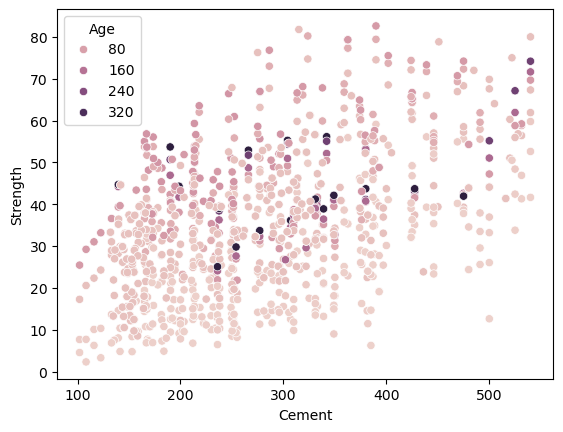

In [30]:
sns.scatterplot(data=df, x=df["Cement"], y=df["Strength"], hue=df["Age"])
plt.show()

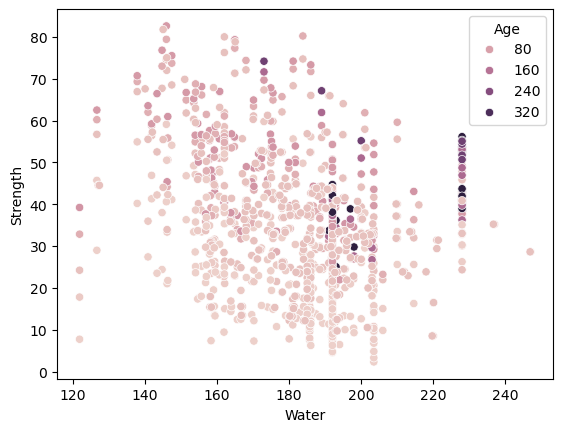

In [32]:
sns.scatterplot(data=df, x=df["Water"], y=df["Strength"], hue=df["Age"])
plt.show()

In [70]:
X = df.drop("Strength", axis=1)
y = df["Strength"]

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.25, random_state=15)

In [84]:
# First weak learner

tree_reg1 = DecisionTreeRegressor(max_depth=4)

tree_reg1.fit(X_train, y_train)

DecisionTreeRegressor(max_depth=4)

In [85]:
y2 = y_train - tree_reg1.predict(X_train) # Residuals 

In [86]:
y2[:5]

919   -10.123129
641    -0.412759
535     4.885238
835     0.858571
583    -7.717987
Name: Strength, dtype: float64

In [87]:
# Second week learner

tree_reg2 = DecisionTreeRegressor(max_depth=4)

tree_reg2.fit(X_train, y2)     # Residualslar minimize edilmeye calisilir.

DecisionTreeRegressor(max_depth=4)

In [88]:
y3 = y2 - tree_reg2.predict(X_train) # X_train e gore predict ettik cunku egitim sirasinda yaptigi hatalara gore kendini duzeltecek.

y3[:5]

919   -9.477082
641    0.233288
535    4.873612
835    1.504618
583   -0.266276
Name: Strength, dtype: float64

In [89]:
# Third weak learner

tree_reg3 = DecisionTreeRegressor(max_depth=4)

tree_reg3.fit(X_train, y3)

DecisionTreeRegressor(max_depth=4)

In [90]:
y4 = y3 - tree_reg3.predict(X_train)

y4[:5]

919   -9.239303
641    4.999993
535    5.111392
835    1.742398
583   -1.293633
Name: Strength, dtype: float64

In [91]:
# forth weak learner

tree_reg4 = DecisionTreeRegressor(max_depth=4)

tree_reg4.fit(X_train, y4)

DecisionTreeRegressor(max_depth=4)

In [92]:
y5 = y4 - tree_reg4.predict(X_train)

y5[:5]

919   -10.116266
641     4.123029
535     4.234428
835     1.093236
583     4.507455
Name: Strength, dtype: float64

In [93]:
y_pred = sum(tree.predict(X_test) for tree in (tree_reg1, tree_reg2, tree_reg3, tree_reg4))

r2_score(y_test, y_pred)

0.822796824777615

In [106]:
gbr = GradientBoostingRegressor(n_estimators=100, max_depth=3, learning_rate=0.1)

gbr.fit(X_train, y_train)
y_pred1 = gbr.predict(X_test)

r2_score(y_test, y_pred1)

0.9247306198159041

In [107]:
#hyparameter Tuning

In [118]:
params = {
    "n_estimators" : [100,150,200],
    "max_depth" : [3,4,5],
    "loss" : ['squared_error', 'absolute_error', 'huber', 'quantile'],
    "learning_rate" : [0.01, 0.1, 0.5]
}

In [119]:
rscv = RandomizedSearchCV(
    estimator=GradientBoostingRegressor(),
    param_distributions=params,
    cv=5
)

rscv.fit(X_train, y_train)

RandomizedSearchCV(cv=5, estimator=GradientBoostingRegressor(),
                   param_distributions={'learning_rate': [0.01, 0.1, 0.5],
                                        'loss': ['squared_error',
                                                 'absolute_error', 'huber',
                                                 'quantile'],
                                        'max_depth': [3, 4, 5],
                                        'n_estimators': [100, 150, 200]})

In [120]:
rscv.best_params_

{'n_estimators': 200,
 'max_depth': 4,
 'loss': 'squared_error',
 'learning_rate': 0.1}

In [1]:
y_pred2 = rscv.predict(X_test)

NameError: name 'rscv' is not defined

In [122]:
r2_score(y_test, y_pred2)

0.9456291096773164